# E0 · SceneFun3D：数据链路与空间投影检查（场景 421069 / 序列 42444490）

**E0 要回答的问题：** 图像、深度、相机内外参和标注坐标是否对齐？（见[快速验证计划](../docs/research/环境记忆Affordance层_快速验证实验计划_Mac_Isambard_2026-11-05.md) §3）

| | 内容 |
|---|---|
| 数据 | SceneFun3D v1 train，visit 421069，video 42444490（该场景最长的一段）。`hires_wide` RGB、`hires_depth`（**Faro mesh 渲染深度**，不是传感器深度）、`hires_poses`（COLMAP 估计，**Faro 坐标系**）、逐帧内参；不混用 lowres/ARKit 路径。 |
| 场景选择 | 在 16 个候选 train 场景中按功能部件数量挑选：38 个部件，9 种类型全覆盖，压缩下载 0.9 GB。**帧按时间均匀抽取，不看标签。** |
| 分辨率 | 原图 1440×1920（宽×高，竖屏存储）；每 2 个像素取 1（720×960），内参精确缩放。 |
| GT 标注 | 功能区域标注只用于 **ORACLE 诊断**（Step 3、6），不进入任何记忆或模型。 |
| 阈值 | 下面的通过门槛是在这个开发场景上锁定的工程门槛，写入 manifest；不是统计结论。 |

**E0 通过只说明工程链路可用，不说明任何方法有效。**

运行：`conda activate affordance3d`；先下载数据 `python scripts/download_scenefun3d.py --visit 421069 --video 42444490`（约 0.9 GB，可中断，重复执行即续传）；再在仓库根目录 `jupyter lab notebooks/02_scenefun3d_e0.ipynb`，Run All。

## Step 0 · 参数

In [1]:
import json
import sys
import time
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.io as pio
from matplotlib_inline.backend_inline import set_matplotlib_formats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
sys.path.insert(0, str(ROOT))

from affordance3d.e0_checks import (epipolar_inliers, match_features, nearest_distances, reproject_matches,
                                    sift_features, visible_point_counts)
from affordance3d.geometry import backproject, project, rotate_frame_cw, visible_mask
from affordance3d.scenefun3d import (SKY_TO_CW_TURNS, index_sequence, load_frames, load_sequence, pick_partners,
                                     read_annotations, read_laser_scan, read_sky_direction, read_traj_poses,
                                     sky_angle_deg, upright_cw_turns)
from affordance3d.viz import Z_UP_VIEW, frustum_trace, image_row, points_trace, save_html, scene_figure, subsample

pio.renderers.default = "plotly_mimetype"
set_matplotlib_formats("jpeg")
plt.rcParams["figure.dpi"] = 72

VISIT, VIDEO = "421069", "42444490"
DATA = ROOT / "data" / "scenefun3d"  # python scripts/download_scenefun3d.py --visit 421069 --video 42444490
if not (DATA / VISIT / VIDEO / "hires_depth").is_dir():
    raise FileNotFoundError(f"scene data missing under {DATA}; run the download script first")
TOOLKIT = ROOT / "third_party" / "scenefun3d"
SCENE = DATA / VISIT
N_FRAMES = 20                 # plan: start with 10-20 frames, then 40-80
PIXEL_STEP = 2                # 1440x1920 (W x H) -> 720x960
DEPTH_TOL_M = 0.05            # visibility test (projected vs observed depth)
LIFT_STRIDE = 8               # pixel stride when lifting depth for the laser-scan check
MIN_VISIBLE_POINTS = 10       # an element counts as "seen" in a frame with at least this many visible points
PARTNER_MIN_GAP_S, PARTNER_MAX_GAP_S = 0.3, 2.0  # Step 5: partner frame 0.3-2 s after each sampled frame
EPIPOLAR_PX = 1.5             # Step 5: RANSAC fundamental-matrix threshold (image-only match filtering)
DISPLAY_CUT_M = 1.6           # 3D views only: hide scan points this far above the floor (ceiling)
THRESHOLDS = {                # E0 engineering gates, locked on this development scene
    "upright_max_abs_angle_deg": 30.0,
    "depth_to_scan_median_m": 0.01,
    "sift_median_px": 3.0,
    "sift_min_matches": 20,
    "control_ratio": 5.0,
}
OUT = ROOT / "runs" / "scenefun3d_e0"
OUT.mkdir(parents=True, exist_ok=True)

SKY_METADATA = read_sky_direction(TOOLKIT / "benchmark_file_lists" / "arkitscenes" / "metadata.csv", VIDEO)
TURNS_METADATA = SKY_TO_CW_TURNS[SKY_METADATA]
TURNS = upright_cw_turns(list(read_traj_poses(SCENE / VIDEO / "hires_poses.traj").values()))
print(f"data: {DATA.relative_to(ROOT)}")
print(f"ARKitScenes metadata: sky_direction = {SKY_METADATA} (would mean {TURNS_METADATA} clockwise turns)")
print(f"poses of the stored hires frames: {TURNS} clockwise turns needed -> using {TURNS}")

data: data/scenefun3d
ARKitScenes metadata: sky_direction = Left (would mean 1 clockwise turns)
poses of the stored hires frames: 0 clockwise turns needed -> using 0


## Step 1 · 资产清单与帧选择

从全部可用帧（同时具备 RGB、深度、内参和时间上足够近的位姿）中按时间均匀取 `N_FRAMES` 帧，保留时间顺序。

,files,size (MB)
asset,,
421069_annotations.json,1,1.7
421069_crop_mask.npy,1,8.9
421069_descriptions.json,1,0.0
421069_laser_scan.ply,1,133.2
42444490,1,0.1
42444490/hires_depth,1025,422.7
42444490/hires_poses.traj,1,0.1
42444490/hires_wide,1025,349.8
42444490/hires_wide_intrinsics,1025,0.0


,timestamp (s),pose gap (ms),size (H×W),valid depth,depth range (m)
frame,,,,,
0,1231.487,0.0,960×720,100%,0.31 – 0.51
1,1236.868,0.0,960×720,100%,0.95 – 2.01
2,1243.482,0.0,960×720,94%,0.81 – 2.78
3,1249.679,0.0,960×720,86%,0.80 – 1.87
4,1257.376,0.0,960×720,95%,0.68 – 4.62
5,1262.674,0.0,960×720,93%,0.72 – 4.18
6,1268.072,0.0,960×720,99%,0.65 – 1.95
7,1273.470,0.0,960×720,100%,0.77 – 2.12
8,1280.567,0.0,960×720,84%,0.58 – 1.63


1025 usable frames over 113 s; loaded 20 (one every ~5.9 s); raw (1920, 1440) -> processed (960, 720); load 1.0 s (50 ms/frame incl. full-res decode)


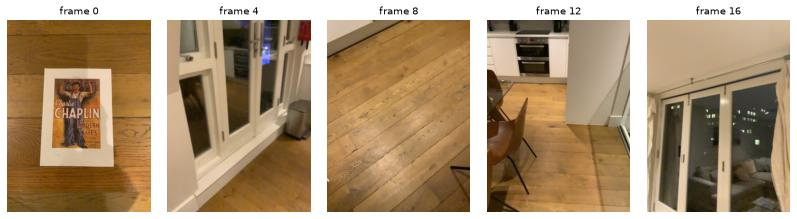

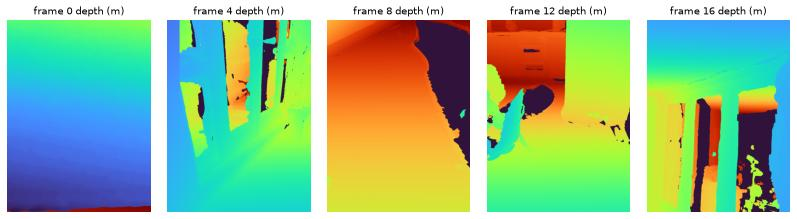

In [2]:
def describe(path: Path) -> dict:
    files = [p for p in path.glob("*") if p.is_file()] if path.is_dir() else [path]  # asset folders are flat
    return {"asset": path.relative_to(SCENE).as_posix(), "files": len(files),
            "size (MB)": round(sum(p.stat().st_size for p in files) / 1e6, 1)}

display(pd.DataFrame([describe(p) for p in sorted(SCENE.iterdir())] +
                     [describe(p) for p in sorted((SCENE / VIDEO).iterdir())]).set_index("asset"))

start = time.perf_counter()
sample = load_sequence(DATA, VISIT, VIDEO, N_FRAMES, TURNS, PIXEL_STEP)
load_seconds = time.perf_counter() - start
frames = sample.frames

display(pd.DataFrame([{
    "frame": f.index, "timestamp (s)": t, "pose gap (ms)": round(gap * 1000, 1),
    "size (H×W)": f"{f.image_hw[0]}×{f.image_hw[1]}",
    "valid depth": f"{(f.depth_m > 0).mean():.0%}",
    "depth range (m)": f"{f.depth_m[f.depth_m > 0].min():.2f} – {f.depth_m.max():.2f}",
} for f, t, gap in zip(frames, sample.timestamps, sample.pose_gaps_s)]).set_index("frame"))

span = float(sample.timestamps[-1]) - float(sample.timestamps[0])
print(f"{sample.n_frames_available} usable frames over {span:.0f} s; loaded {len(frames)} "
      f"(one every ~{span / (len(frames) - 1):.1f} s); raw {sample.raw_hw} -> processed {frames[0].image_hw}; "
      f"load {load_seconds:.1f} s ({load_seconds / len(frames) * 1000:.0f} ms/frame incl. full-res decode)")

shown = frames[:: max(1, len(frames) // 5)][:5]
fig, _ = image_row([f.rgb for f in shown], [f"frame {f.index}" for f in shown])
fig.savefig(OUT / "step1_rgb.jpg", dpi=72)
fig, _ = image_row([f.depth_m for f in shown], [f"frame {f.index} depth (m)" for f in shown], cmap="turbo")
fig.savefig(OUT / "step1_depth.jpg", dpi=72)
plt.show()

## Step 2 · 图像朝向核查

ARKitScenes 元数据说这段视频 `sky_direction = Left`，但那是针对横屏的低分辨率帧。SceneFun3D 的 hires 帧以 1440×1920 **竖屏**存储（见内参文件），朝向可能已经不同。所以转正所需的旋转量**由位姿决定**：计算世界 +z（Faro 坐标系 z 轴朝上，已由地面所在的水平层确认）在图像中的方向，0° 表示图像正上方；多帧投票。

如果旋转量对，处理后所有帧都应接近 0°。对照：如果照元数据旋转，会偏 90°。图像、深度、内参和位姿始终**一起**旋转（单元测试保证旋转前后反投影的世界点完全相同）。

,used (from poses),if following metadata
mean,0.065,90.065
min,-7.300,82.700
max,10.100,100.100


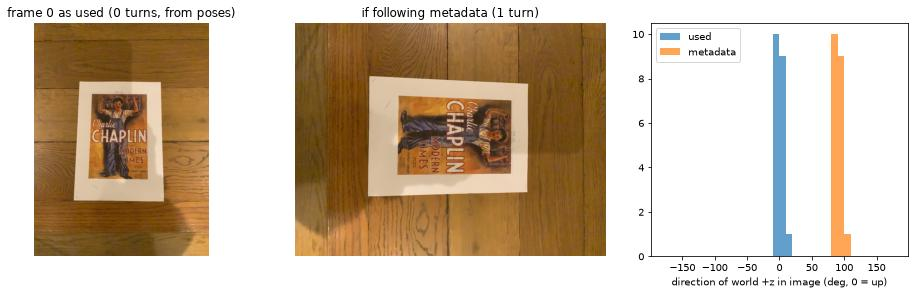

upright check: PASS


In [3]:
metadata_frames = [rotate_frame_cw(f, (TURNS_METADATA - TURNS) % 4) for f in frames]  # what the metadata would give
angles = pd.DataFrame({"used (from poses)": [sky_angle_deg(f.cam_to_world) for f in frames],
                       "if following metadata": [sky_angle_deg(f.cam_to_world) for f in metadata_frames]}).round(1)
display(angles.describe().loc[["mean", "min", "max"]])
upright_ok = bool(angles["used (from poses)"].abs().max() < THRESHOLDS["upright_max_abs_angle_deg"])

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), gridspec_kw={"width_ratios": [3, 4, 3]})
axes[0].imshow(frames[0].rgb); axes[0].set_title(f"frame 0 as used ({TURNS} turns, from poses)")
axes[1].imshow(metadata_frames[0].rgb); axes[1].set_title(f"if following metadata ({TURNS_METADATA} turn)")
for axis in axes[:2]:
    axis.set_axis_off()
axes[2].hist(angles["used (from poses)"], bins=36, range=(-180, 180), alpha=0.7, label="used")
axes[2].hist(angles["if following metadata"], bins=36, range=(-180, 180), alpha=0.7, label="metadata")
axes[2].set_xlabel("direction of world +z in image (deg, 0 = up)"); axes[2].legend()
fig.tight_layout(); fig.savefig(OUT / "step2_orientation.jpg", dpi=72)
plt.show()
print("upright check:", "PASS" if upright_ok else "FAIL")

## Step 3 · RGB / 深度 / 功能区域对照（ORACLE）

把激光扫描上的人工功能标注点投影到图像里，只画出通过深度遮挡测试的点。**这里用了 GT，只用于判断几何是否对齐**：如果坐标系、位姿或旋转有问题，标注会偏离把手、旋钮、开关等部件。这一步需要人工看图确认。

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


laser scan: 8,880,684 points (7,921,109 after crop); 38 functional elements


,elements
rotate,11
plug_in,7
hook_turn,5
tip_push,5
hook_pull,4
key_press,2
pinch_pull,2
unplug,1
foot_push,1


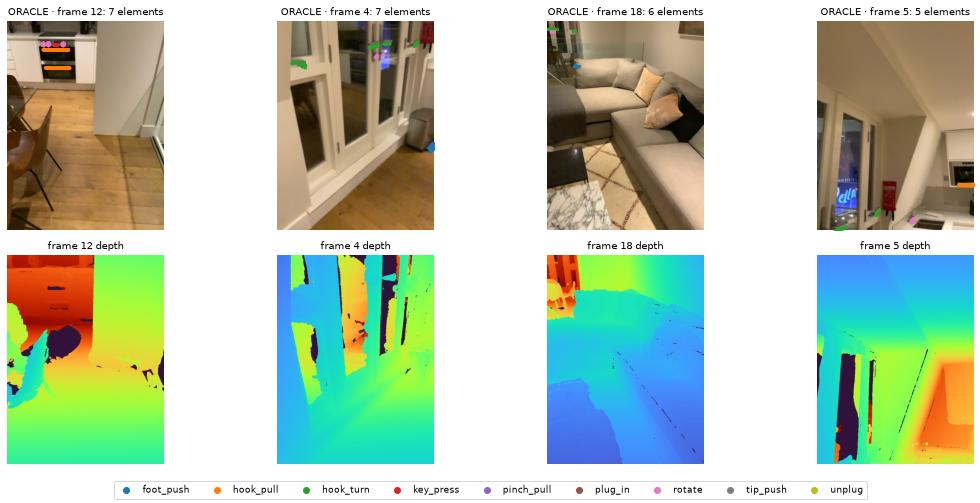

In [4]:
scan_xyz, scan_rgb = read_laser_scan(SCENE / f"{VISIT}_laser_scan.ply")
crop = np.load(SCENE / f"{VISIT}_crop_mask.npy").astype(bool)
elements = read_annotations(SCENE / f"{VISIT}_annotations.json")
labels = sorted({e.label for e in elements})
palette = plt.get_cmap("tab10")
LABEL_COLOURS = {label: palette(i) for i, label in enumerate(labels)}
print(f"laser scan: {len(scan_xyz):,} points ({crop.sum():,} after crop); {len(elements)} functional elements")
display(pd.Series([e.label for e in elements]).value_counts().rename("elements").to_frame())

def overlay_elements(axis, frame) -> int:
    drawn = 0
    for element in elements:
        points = scan_xyz[element.indices]
        visible = visible_mask(points, frame, DEPTH_TOL_M)
        if visible.sum() < MIN_VISIBLE_POINTS:
            continue
        uv, _, _ = project(points[visible], frame)
        axis.scatter(uv[:, 0], uv[:, 1], s=1, color=LABEL_COLOURS[element.label], alpha=0.6)
        drawn += 1
    return drawn

counts_per_frame = [sum(visible_mask(scan_xyz[e.indices], f, DEPTH_TOL_M).sum() >= MIN_VISIBLE_POINTS
                        for e in elements) for f in frames]
picked = [frames[i] for i in np.argsort(counts_per_frame)[::-1][:4]]  # frames showing the most elements
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for column, frame in enumerate(picked):
    axes[0, column].imshow(frame.rgb)
    n = overlay_elements(axes[0, column], frame)
    axes[0, column].set_title(f"ORACLE · frame {frame.index}: {n} elements", fontsize=10)
    axes[1, column].imshow(frame.depth_m, cmap="turbo")
    axes[1, column].set_title(f"frame {frame.index} depth", fontsize=10)
for axis in axes.flat:
    axis.set_axis_off()
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=l) for l, c in LABEL_COLOURS.items()]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), fontsize=9)
fig.tight_layout(rect=(0, 0.05, 1, 1)); fig.savefig(OUT / "step3_oracle_overlay.jpg", dpi=72)
plt.show()

## Step 4 · 深度与激光扫描是否落在同一坐标系

把每帧深度（每 8 个像素取 1）反投影到世界坐标，计算到最近激光扫描点的距离。它检查**深度单位（毫米→米）和位姿是否在 Faro 坐标系**：单位错 1000 倍或坐标系不对，距离会是米级。

注意：SceneFun3D 的高分辨率深度本身就是用这些位姿从 Faro mesh 渲染的，所以这一项接近“自洽检查”；真正独立的对齐检查是 Step 5。

In [5]:
scan_crop = scan_xyz[crop]
lifted = [backproject(f, stride=LIFT_STRIDE)[0] for f in frames]
start = time.perf_counter()
distances = nearest_distances(np.concatenate(lifted), scan_crop)
kd_seconds = time.perf_counter() - start
per_frame = np.split(distances, np.cumsum([len(p) for p in lifted])[:-1])

depth_scan = pd.DataFrame([{
    "frame": f.index, "points": len(d), "median (mm)": round(np.median(d) * 1000, 1),
    "p90 (mm)": round(np.percentile(d, 90) * 1000, 1), "share < 1 cm": f"{np.mean(d < 0.01):.0%}",
} for f, d in zip(frames, per_frame)]).set_index("frame")
display(depth_scan.T)
depth_scan_median = float(np.median(distances))
depth_ok = depth_scan_median < THRESHOLDS["depth_to_scan_median_m"]
print(f"all frames: median {depth_scan_median * 1000:.1f} mm, p90 {np.percentile(distances, 90) * 1000:.1f} mm "
      f"({len(distances):,} points, KD-tree query {kd_seconds:.1f} s) ->", "PASS" if depth_ok else "FAIL")

heights, edges = np.histogram(scan_crop[:, 2], bins=200)
floor_z = float(edges[np.argmax(heights)])  # densest horizontal slab = floor
below_cut = np.flatnonzero(scan_crop[:, 2] < floor_z + DISPLAY_CUT_M)
scan_keep = below_cut[subsample(len(below_cut), 60_000)]  # display only: ceiling hidden so rooms are visible
print(f"floor at z = {floor_z:.2f} m; 3D views hide scan points more than {DISPLAY_CUT_M} m above the floor")
all_lifted = np.concatenate(lifted)
fig = scene_figure(
    [points_trace(scan_crop[scan_keep], scan_rgb[crop][scan_keep], name="laser scan (cropped)", size=1.2, max_points=60_000),
     points_trace(all_lifted, values=np.minimum(distances, 0.05) * 1000, name="depth points: distance to scan (mm)",
                  colorscale="Turbo", cmin=0, cmax=50, size=1.5, visible="legendonly"),
     *[frustum_trace(f, "black", depth=0.2) for f in frames]],
    "Step 4 · laser scan + cameras (click legend: depth points coloured by distance to scan)", height=620, view=Z_UP_VIEW)
save_html(fig, OUT / "step4_scan_and_cameras.html")
fig

frame,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
points,10800,10800,10157,9272,10286,10078,10733,10751,9076,10767,9784,10756,10377,8765,10556,10744,9267,10283,10769,10594
median (mm),2.8,2.2,2.2,2.5,2.5,2.2,2.3,2.2,2.1,2.2,2.5,2.7,2.7,2.4,2.5,2.2,2.3,2.4,2.3,2.1
p90 (mm),3.5,3.4,3.6,6.0,17.5,12.5,4.1,3.9,3.1,4.5,21.4,12.4,7.0,3.7,6.8,3.4,16.2,23.1,14.7,3.6
share < 1 cm,100%,95%,97%,93%,86%,89%,94%,94%,96%,93%,81%,89%,92%,96%,91%,96%,86%,84%,88%,92%


all frames: median 2.4 mm, p90 6.3 mm (204,615 points, KD-tree query 4.9 s) -> PASS
floor at z = 299.87 m; 3D views hide scan points more than 1.6 m above the floor


## Step 5 · 跨帧对应的像素误差（E0 核心，独立于标注）

做法：给每个抽样帧（源帧，有深度）配一个 0.3–2 s 之后的“搭档帧”（只需要 RGB 和位姿），保证两帧有足够重叠。

1. 用 SIFT 在两帧之间做特征匹配，**只用图像**；
2. 用 RANSAC 基础矩阵剔除几何上不可能的错配。这一步也只用图像，**不使用我们的位姿或深度**，所以不会让结果偏向位姿；
3. 用源帧的深度和位姿预测每个匹配点在搭档帧中的位置，与实际匹配位置比较。

RGB、深度、内参、位姿、旋转、时间戳配对中任何一项出错，误差都会变大；“平均偏移”接近 (0, 0) 说明没有整体平移或错位。对照组：给搭档帧故意换成源帧的位姿。少于 20 个已验证匹配的帧对不计入汇总（匹配太少时 RANSAC 也可能被错配骗过），但仍列在表中。

,source t,partner t,Δt (s),SIFT matches,epipolar-verified,with depth,median (px),p90 (px),share < 3 px,"mean offset (u, v)",control median (px)
frame,,,,,,,,,,,
0,1231.487,1231.870,0.38,495.0,446.0,446.0,3.09,4.7,47%,"(-0.4, +2.9)",20.6
1,1236.868,1237.268,0.40,78.0,58.0,58.0,2.03,3.0,88%,"(-0.2, -1.7)",213.0
2,1243.482,1243.882,0.40,219.0,145.0,145.0,5.14,12.5,8%,"(-1.5, +0.4)",151.6
3,1249.679,1250.079,0.40,47.0,25.0,22.0,4.26,14.4,32%,"(-1.5, +1.7)",155.2
4,1257.376,1257.776,0.40,73.0,43.0,43.0,2.23,10.9,67%,"(+0.8, +10.5)",156.4
5,1262.674,1263.074,0.40,72.0,45.0,36.0,1.57,2.6,92%,"(+1.0, +0.3)",141.0
6,1268.072,1268.372,0.30,57.0,26.0,21.0,5.72,8.2,33%,"(-3.2, +13.5)",183.3
7,1273.470,1273.869,0.40,89.0,51.0,50.0,2.15,5.1,70%,"(+0.8, -1.0)",215.5
8,1280.567,1280.967,0.40,86.0,67.0,64.0,1.18,1.8,97%,"(-2.1, -5.5)",163.5


18/20 pairs with >= 20 verified matches; median of pair medians 1.88 px (worst 5.72) vs control 146.3 px (2.5 s) -> PASS


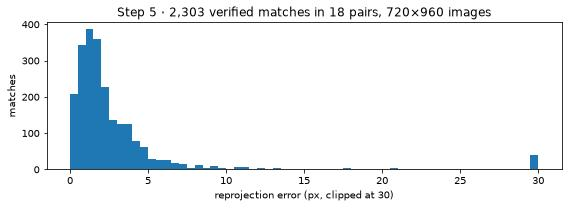

In [6]:
index = index_sequence(DATA, VISIT, VIDEO)
partner_times = pick_partners(sample.timestamps, index.rgb_times, PARTNER_MIN_GAP_S, PARTNER_MAX_GAP_S)

pair_rows, pair_results = [], []
start = time.perf_counter()
for src, src_t, partner_t in zip(frames, sample.timestamps, partner_times):
    if partner_t is None:
        pair_rows.append({"frame": src.index, "source t": src_t, "partner t": "-"})
        continue
    (dst,) = load_frames(index, [partner_t], TURNS, PIXEL_STEP, first_position=src.index)
    uv_a, uv_b = match_features(sift_features(src.rgb), sift_features(dst.rgb))
    verified = epipolar_inliers(uv_a, uv_b, EPIPOLAR_PX)
    result = reproject_matches(src, dst, uv_a[verified], uv_b[verified])
    control = reproject_matches(src, replace(dst, cam_to_world=src.cam_to_world), uv_a[verified], uv_b[verified])
    errors = result.errors_px
    pair_results.append((src, dst, result, src_t, partner_t))
    offset = np.mean(result.predicted_uv - result.dst_uv, axis=0) if len(errors) else (np.nan, np.nan)
    pair_rows.append({
        "frame": src.index, "source t": src_t, "partner t": partner_t,
        "Δt (s)": round(float(partner_t) - float(src_t), 2), "SIFT matches": len(uv_a),
        "epipolar-verified": int(verified.sum()), "with depth": len(errors),
        "median (px)": round(float(np.median(errors)), 2) if len(errors) else np.nan,
        "p90 (px)": round(float(np.percentile(errors, 90)), 1) if len(errors) else np.nan,
        "share < 3 px": f"{np.mean(errors < 3):.0%}" if len(errors) else "-",
        "mean offset (u, v)": f"({offset[0]:+.1f}, {offset[1]:+.1f})",
        "control median (px)": round(float(np.median(control.errors_px)), 1) if len(control.errors_px) else np.nan,
    })
sift_seconds = time.perf_counter() - start
pairs = pd.DataFrame(pair_rows).set_index("frame")
display(pairs)

usable = pairs[pairs["with depth"] >= THRESHOLDS["sift_min_matches"]]
sift_median = float(usable["median (px)"].median())
control_median = float(usable["control median (px)"].median())
sift_ok = sift_median < THRESHOLDS["sift_median_px"] and control_median > THRESHOLDS["control_ratio"] * sift_median
print(f"{len(usable)}/{len(pairs)} pairs with >= {THRESHOLDS['sift_min_matches']} verified matches; median of pair medians "
      f"{sift_median:.2f} px (worst {usable['median (px)'].max():.2f}) vs control {control_median:.1f} px "
      f"({sift_seconds:.1f} s) ->", "PASS" if sift_ok else "FAIL")

counted = [r for r in pair_results if len(r[2].errors_px) >= THRESHOLDS["sift_min_matches"]]
all_errors = np.concatenate([r[2].errors_px for r in counted]) if counted else np.empty(0)
fig, axis = plt.subplots(figsize=(8, 3))
axis.hist(np.clip(all_errors, 0, 30), bins=60, range=(0, 30))
axis.set_xlabel("reprojection error (px, clipped at 30)"); axis.set_ylabel("matches")
axis.set_title(f"Step 5 · {len(all_errors):,} verified matches in {len(counted)} pairs, "
               f"{frames[0].image_hw[1]}×{frames[0].image_hw[0]} images")
fig.tight_layout(); fig.savefig(OUT / "step5_error_hist.jpg", dpi=72)
plt.show()

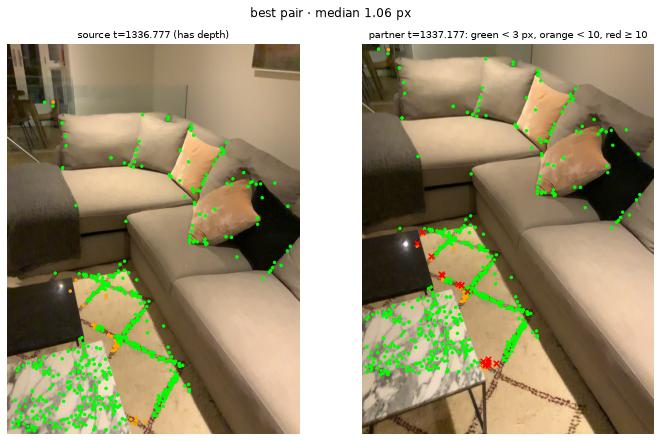

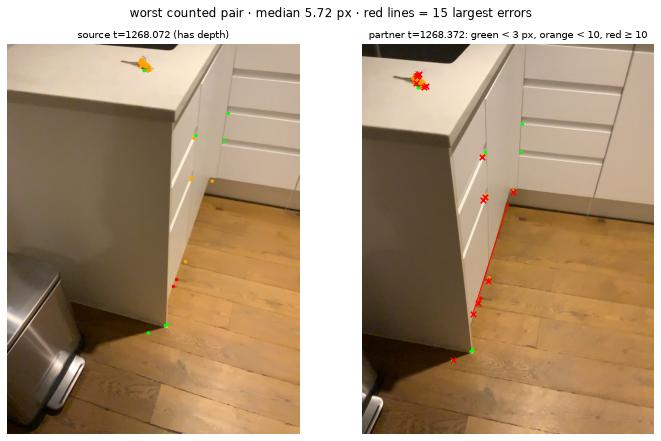

In [7]:
def show_pair(src, dst, result, src_t: str, dst_t: str, title: str) -> plt.Figure:
    errors = result.errors_px
    colours = np.where(errors < 3, "lime", np.where(errors < 10, "orange", "red"))
    fig, axes = plt.subplots(1, 2, figsize=(10, 6.2))
    axes[0].imshow(src.rgb); axes[0].scatter(*result.src_uv.T, s=6, c=colours)
    axes[1].imshow(dst.rgb); axes[1].scatter(*result.dst_uv.T, s=6, c=colours)
    for i in np.argsort(errors)[::-1][:15]:  # mismatch examples: observed (dot) -> predicted (cross)
        axes[1].plot(*np.stack([result.dst_uv[i], result.predicted_uv[i]]).T, color="red", lw=1)
        axes[1].scatter(*result.predicted_uv[i], marker="x", c="red", s=30)
    axes[0].set_title(f"source t={src_t} (has depth)", fontsize=10)
    axes[1].set_title(f"partner t={dst_t}: green < 3 px, orange < 10, red ≥ 10", fontsize=10)
    for axis in axes:
        axis.set_axis_off()
    fig.suptitle(title); fig.tight_layout()
    return fig

ranked = sorted(counted, key=lambda r: np.median(r[2].errors_px))
if ranked:
    best, worst = ranked[0], ranked[-1]
    show_pair(*best, f"best pair · median {np.median(best[2].errors_px):.2f} px").savefig(OUT / "step5_best_pair.jpg", dpi=72)
    show_pair(*worst, f"worst counted pair · median {np.median(worst[2].errors_px):.2f} px · red lines = 15 largest errors"
              ).savefig(OUT / "step5_worst_pair.jpg", dpi=72)
    plt.show()

## Step 6 · 功能部件被观察到的情况（为 E1 做准备，ORACLE）

统计每个功能部件在哪些帧中可见（至少 10 个标注点通过深度遮挡测试）。E1 需要“历史中看到过、当前看不到”的部件，以及在多帧中可见的部件做跨视角检查。

,elements,median_points,seen_in_any,seen_in_2_plus
label,,,,
foot_push,1,1325.0,1,1
hook_pull,4,882.0,4,1
hook_turn,5,171.0,4,3
key_press,2,386.5,2,0
pinch_pull,2,20.0,0,0
plug_in,7,105.0,5,1
rotate,11,67.0,7,4
tip_push,5,30.0,2,0
unplug,1,158.0,1,0


26/38 elements seen in at least one of 20 frames; 10 in two or more


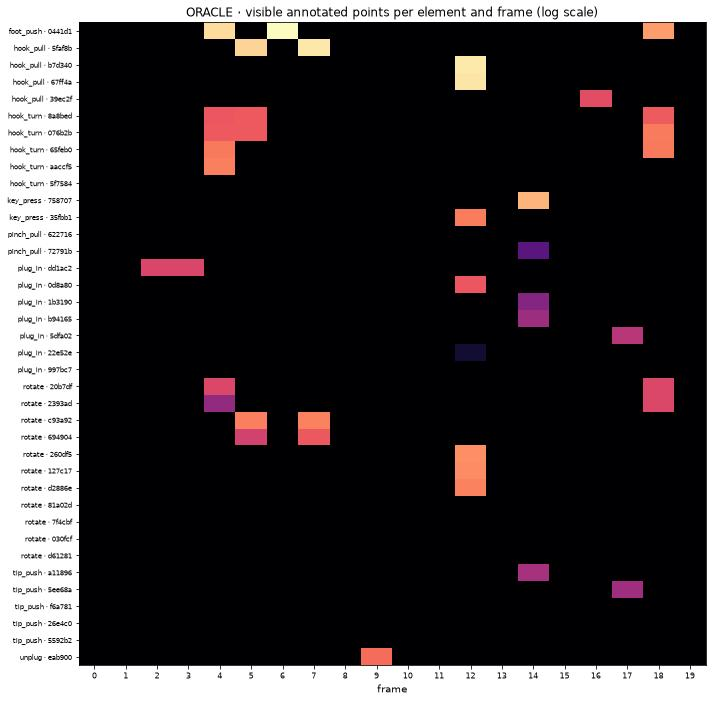

In [8]:
element_points = [scan_xyz[e.indices] for e in elements]
counts = visible_point_counts(element_points, frames, DEPTH_TOL_M)
seen = counts >= MIN_VISIBLE_POINTS
frames_per_element = seen.sum(axis=1)

summary = pd.DataFrame({"label": [e.label for e in elements], "points": [len(e.indices) for e in elements],
                        "frames seen": frames_per_element})
display(summary.groupby("label").agg(elements=("points", "size"), median_points=("points", "median"),
                                     seen_in_any=("frames seen", lambda s: int((s >= 1).sum())),
                                     seen_in_2_plus=("frames seen", lambda s: int((s >= 2).sum()))))
print(f"{int((frames_per_element >= 1).sum())}/{len(elements)} elements seen in at least one of {len(frames)} frames; "
      f"{int((frames_per_element >= 2).sum())} in two or more")

order = np.lexsort((-frames_per_element, [e.label for e in elements]))
fig, axis = plt.subplots(figsize=(10, 0.22 * len(elements) + 1.5))
axis.imshow(np.log1p(counts[order]), aspect="auto", cmap="magma")
axis.set_yticks(range(len(elements)), [f"{elements[i].label} · {elements[i].annot_id[:6]}" for i in order], fontsize=7)
axis.set_xticks(range(len(frames)), [f.index for f in frames], fontsize=8)
axis.set_xlabel("frame"); axis.set_title("ORACLE · visible annotated points per element and frame (log scale)")
fig.tight_layout(); fig.savefig(OUT / "step6_visibility.jpg", dpi=72)
plt.show()

### 6b · 同一部件的多个观察（ORACLE，人工核对）

对在两帧以上可见的部件，并排放大显示它在不同帧中的位置（叠加的点是激光扫描上的人工标注，经深度遮挡测试后投影到图像）。**如果坐标、位姿和朝向都对，同一部件在每个视角下都应落在同一个把手、旋钮或开关上。**

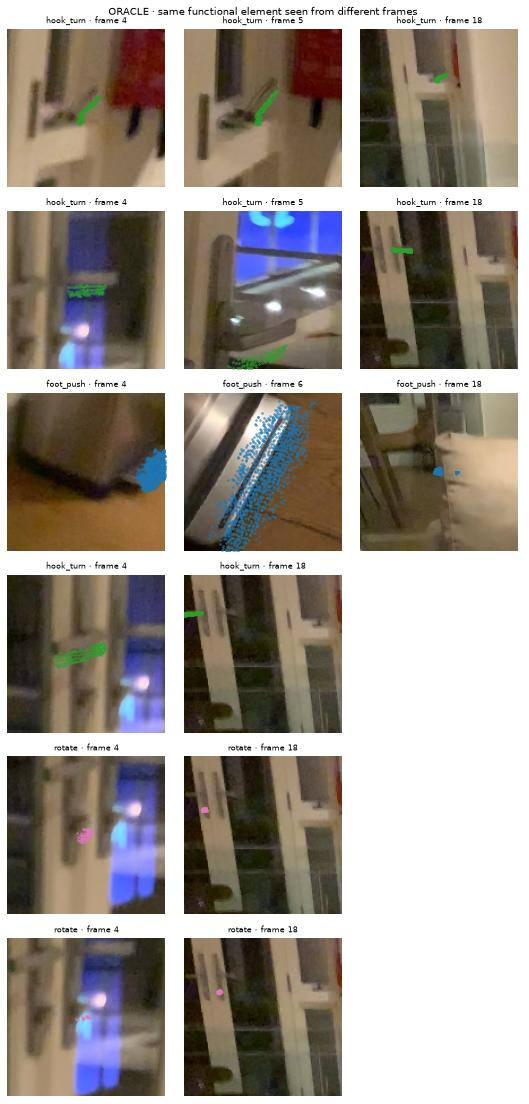

In [9]:
CROP_HALF = 70  # px at the processed resolution

def element_crop(frame, points: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    visible = visible_mask(points, frame, DEPTH_TOL_M)
    uv, _, _ = project(points[visible], frame)
    height, width = frame.image_hw
    centre_u, centre_v = np.median(uv, axis=0).round().astype(int)
    u0 = int(np.clip(centre_u - CROP_HALF, 0, width - 2 * CROP_HALF))
    v0 = int(np.clip(centre_v - CROP_HALF, 0, height - 2 * CROP_HALF))
    return frame.rgb[v0:v0 + 2 * CROP_HALF, u0:u0 + 2 * CROP_HALF], uv - [u0, v0]

multi_view = [i for i in np.argsort(-frames_per_element, kind="stable") if frames_per_element[i] >= 2][:6]
fig, axes = plt.subplots(max(1, len(multi_view)), 3, figsize=(7.5, 2.6 * max(1, len(multi_view))), squeeze=False)
for row, i in enumerate(multi_view):
    views = [frames[k] for k in np.flatnonzero(seen[i])][:3]
    for col in range(3):
        axis = axes[row, col]
        axis.set_axis_off()
        if col < len(views):
            crop, uv = element_crop(views[col], element_points[i])
            axis.imshow(crop)
            axis.scatter(uv[:, 0], uv[:, 1], s=3, color=LABEL_COLOURS[elements[i].label], alpha=0.5)
            axis.set_xlim(0, crop.shape[1]); axis.set_ylim(crop.shape[0], 0)  # long parts must not rescale the crop
            axis.set_title(f"{elements[i].label} · frame {views[col].index}", fontsize=8)
fig.suptitle("ORACLE · same functional element seen from different frames", fontsize=10)
fig.tight_layout(); fig.savefig(OUT / "step6b_multiview_crops.jpg", dpi=90)
plt.show()

In [10]:
traces = [points_trace(scan_crop[scan_keep], "lightgrey", name="laser scan", size=1, max_points=60_000)]
for label in labels:
    pts = np.concatenate([scan_xyz[e.indices] for e in elements if e.label == label])
    r, g, b, _ = LABEL_COLOURS[label]
    traces.append(points_trace(pts, f"rgb({int(r * 255)},{int(g * 255)},{int(b * 255)})", name=label, size=2.5))
traces += [frustum_trace(f, "black", depth=0.2) for f in frames]
fig = scene_figure(traces, "Step 6 · ORACLE functional elements by type + sampled cameras", height=620, view=Z_UP_VIEW)
save_html(fig, OUT / "step6_elements.html")
fig

## Step 7 · 资源与 E0 结论

In [11]:
frame_mb = sum(f.rgb.nbytes + f.depth_m.nbytes for f in frames) / 2**20
resources = {
    "frame load (full-res decode + subsample + rotate)": f"{load_seconds / len(frames) * 1000:.0f} ms/frame",
    "frames in memory": f"{frame_mb:.0f} MB for {len(frames)} frames at {frames[0].image_hw[0]}×{frames[0].image_hw[1]}",
    "laser scan": f"{len(scan_xyz):,} points",
    "depth → scan KD-tree check": f"{kd_seconds:.1f} s",
    "SIFT + reprojection": f"{sift_seconds / max(1, len(pairs)):.2f} s/pair",
    "scene data on disk": f"{sum(p.stat().st_size for p in SCENE.rglob('*') if p.is_file()) / 1e9:.2f} GB",
}
display(pd.Series(resources, name="value").to_frame())

checks = pd.DataFrame([
    {"check": "images upright (rotation from poses)", "result": "PASS" if upright_ok else "FAIL",
     "evidence": f"max |angle| {angles['used (from poses)'].abs().max():.1f}° (gate {THRESHOLDS['upright_max_abs_angle_deg']}°); "
                 f"metadata '{SKY_METADATA}' would be off by ~{abs(angles['if following metadata'].median()):.0f}°"},
    {"check": "depth units + Faro frame", "result": "PASS" if depth_ok else "FAIL",
     "evidence": f"median distance to scan {depth_scan_median * 1000:.1f} mm (gate {THRESHOLDS['depth_to_scan_median_m'] * 1000:.0f} mm)"},
    {"check": "cross-frame alignment (SIFT)", "result": "PASS" if sift_ok else "FAIL",
     "evidence": f"{sift_median:.2f} px vs wrong-pose control {control_median:.1f} px (gate {THRESHOLDS['sift_median_px']} px)"},
    {"check": "annotations on the right parts", "result": "VISUAL", "evidence": "inspect Step 3 (ORACLE overlay)"},
]).set_index("check")
display(checks)

manifest = {
    "experiment": "E0 SceneFun3D data and projection check",
    "data": {"dataset": "SceneFun3D v1 (train)", "visit_id": VISIT, "video_id": VIDEO,
             "sky_direction_metadata": SKY_METADATA, "cw_turns_from_poses": TURNS,
             "assets": sorted(p.relative_to(SCENE).as_posix() for p in SCENE.iterdir()) + sorted(p.name for p in (SCENE / VIDEO).iterdir()),
             "timestamps": sample.timestamps, "n_frames_available": sample.n_frames_available,
             "raw_hw": list(sample.raw_hw), "processed_hw": list(frames[0].image_hw)},
    "config": {"n_frames": N_FRAMES, "pixel_step": PIXEL_STEP, "depth_tol_m": DEPTH_TOL_M, "lift_stride": LIFT_STRIDE,
               "min_visible_points": MIN_VISIBLE_POINTS, "partner_gap_s": [PARTNER_MIN_GAP_S, PARTNER_MAX_GAP_S],
               "epipolar_px": EPIPOLAR_PX, "thresholds": THRESHOLDS},
    "gt_usage": "functional annotations used only for ORACLE overlays/visibility (Steps 3, 6); no model or memory input",
    "results": {"upright": upright_ok, "depth_to_scan_median_m": depth_scan_median, "sift_median_px": sift_median,
                "sift_control_median_px": control_median, "sift_pairs_counted": len(usable),
                "pairs": pairs.reset_index().to_dict(orient="records"),
                "elements_seen_any": int((frames_per_element >= 1).sum()),
                "elements_seen_2plus": int((frames_per_element >= 2).sum()), "n_elements": len(elements)},
    "resources": resources,
}
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False, default=float))
print("saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")

,value
frame load (full-res decode + subsample + rotate),50 ms/frame
frames in memory,92 MB for 20 frames at 960×720
laser scan,"8,880,684 points"
depth → scan KD-tree check,4.9 s
SIFT + reprojection,0.12 s/pair
scene data on disk,0.92 GB


,result,evidence
check,,
images upright (rotation from poses),PASS,max |angle| 10.1° (gate 30.0°); metadata 'Left...
depth units + Faro frame,PASS,median distance to scan 2.4 mm (gate 10 mm)
cross-frame alignment (SIFT),PASS,1.88 px vs wrong-pose control 146.3 px (gate 3...
annotations on the right parts,VISUAL,inspect Step 3 (ORACLE overlay)


saved:
  manifest.json
  plotly.min.js
  step1_depth.jpg
  step1_rgb.jpg
  step2_orientation.jpg
  step3_oracle_overlay.jpg
  step4_scan_and_cameras.html
  step5_best_pair.jpg
  step5_error_hist.jpg
  step5_worst_pair.jpg
  step6_elements.html
  step6_visibility.jpg
  step6b_multiview_crops.jpg


### 读结果的方式

- 三项自动检查都 PASS，且 Step 3 的 ORACLE 标注确实落在对应部件上 → **E0 工程链路可用**，可以把帧数扩到 40–80 帧（改 `N_FRAMES` 后 Run All），再进入 E1。
- 任何一项 FAIL → 先修数据和坐标，不启动模型或记忆实验（计划 §3 的继续条件）。
- 即使全部通过，也只说明投影链路可用；不说明任何特征或方法有效。

### 本次运行记录（2026-11-06，完整数据 1025 帧中均匀取 20 帧，720×960）

以下数字和观察针对这次执行；改动帧数或参数后应重新核对。同日先在部分下载的数据（28 帧）上跑过一次，结论一致。

- **朝向：** ARKitScenes 元数据为 `Left`，但 hires 帧以竖屏存储时已经是正的；由位姿判断需要旋转 0 次。照元数据旋转会让所有帧偏 90°。**今后读取 SceneFun3D hires 帧应以位姿为准，不能直接使用 `sky_direction`。**
- **深度与扫描：** 到激光扫描的中位距离 2.4 mm（p90 6.3 mm），单位与 Faro 坐标系一致。
- **跨帧对齐：** 18/20 个帧对有足够的已验证匹配（最后一帧没有搭档帧，另一对只有 18 个匹配），误差中位数为 1.88 px（最差 5.72 px），错误位姿对照为 146 px。误差较大的帧对多数没有整体偏移，误差分散在各个方向。
- **误差来源（未证实）：** 细长物体（灯杆、电线）和靠垫上的误差明显更大，可能因为 5 mm 网格表达不了细物体，或者可移动物体在扫描和拍摄之间位置变了（渲染深度来自扫描时刻的几何）。最差的三对图像偏模糊、相机转得较快（约 30°/s），但在 18 对中与误差的相关性很弱（Spearman 约 0.2），不能确定是运动模糊。
- **一个方法修正：** 第一版只比较相邻抽样帧、不剔除错配，结果被大量 SIFT 错误匹配污染（预测位置落在图外）。改为“搭档帧 + 仅基于图像的对极检验”后，门槛（3 px）不变。
- **ORACLE 标注：** 水龙头阀门、烤箱门把手、门把手在不同视角下都落在同一实物上；foot_push 在远处视角下点很少，需人工复核。
- **对 E1 的提示：** 20 帧中 38 个部件有 26 个可见，10 个在两帧以上可见；部件中位数只有 106 个标注点（几厘米大小）。E1 需要扩到 40–80 帧，并重点检查小部件是否小于 DINOv2 的 patch 分辨率。